In [1]:
"""
Social Network Visualization with Improved Label Legibility

This script creates interactive social network visualizations using NetworkX,
Holoviews, and Datashader with configurable label styling options.

"""

import pandas as pd
from pathlib import Path
import networkx as nx
from sklearn.decomposition import PCA
import numpy as np
from bokeh.plotting import figure, from_networkx, show
from bokeh.models import (
    HoverTool,
    ColumnDataSource,
    Circle,
    MultiLine,
    LabelSet,
    GraphRenderer,
    StaticLayoutProvider,
)

# from bokeh.palettes import Spectral8
import graspologic
import holoviews as hv
from holoviews import opts
import holoviews.operation.datashader as hd
import panel as pn
from node2vec import Node2Vec  # new import for node embeddings


In [ ]:
# DATA_PATH = Path("../data/tweets_2023_11_week4.parquet")
DATA_PATH = Path("../data/tweets_2023_11_15_to_2023_12_15.parquet")

# Define variables used in plot titles
ego_node = "network"  # Default name for network analysis
fourth_week_start = pd.Timestamp("2023-11-1", tz="UTC")
fourth_week_end = pd.Timestamp("2023-11-30", tz="UTC")


In [131]:
df = pd.read_parquet(DATA_PATH)


In [132]:
df.head()
"""
	tweet_id	account_id	username	account_display_name	created_at	full_text	retweet_count	favorite_count	reply_to_tweet_id	reply_to_user_id	reply_to_username	quoted_tweet_id	conversation_id
0	1728926591877808515	881192533056827392	goblinodds	goblin	2023-11-26T23:59:56+00:00	@mechanical_monk --thinking "oh no what a wast...	0	4	1728926283818762524	881192533056827392	goblinodds	None	1728859285013307870
1	1728926513314361364	322603863	exgenesis	❤️‍🔥 xiq	2023-11-26T23:59:37+00:00	oh man just finished the hunter x hunter anime...	0	37	None	None	None	None	1728926513314361364
2	1728926513863766226	282948199	algekalipso	Captain Pleasure, Andrés Gómez Emilsson	2023-11-26T23:59:37+00:00	It's not for everyone. I think that if one is ...	0	4	1728925172642746465	204967813	samuelxgarcia	None	None

"""


'\n\ttweet_id\taccount_id\tusername\taccount_display_name\tcreated_at\tfull_text\tretweet_count\tfavorite_count\treply_to_tweet_id\treply_to_user_id\treply_to_username\tquoted_tweet_id\tconversation_id\n0\t1728926591877808515\t881192533056827392\tgoblinodds\tgoblin\t2023-11-26T23:59:56+00:00\t@mechanical_monk --thinking "oh no what a wast...\t0\t4\t1728926283818762524\t881192533056827392\tgoblinodds\tNone\t1728859285013307870\n1\t1728926513314361364\t322603863\texgenesis\t❤️\u200d🔥 xiq\t2023-11-26T23:59:37+00:00\toh man just finished the hunter x hunter anime...\t0\t37\tNone\tNone\tNone\tNone\t1728926513314361364\n2\t1728926513863766226\t282948199\talgekalipso\tCaptain Pleasure, Andrés Gómez Emilsson\t2023-11-26T23:59:37+00:00\tIt\'s not for everyone. I think that if one is ...\t0\t4\t1728925172642746465\t204967813\tsamuelxgarcia\tNone\tNone\n\n'

In [133]:
# let's see what ppl were talking about at the time
pd.set_option("display.max_colwidth", None)
df = df.set_index("tweet_id", inplace=False, drop=False)
df.sort_values("favorite_count", ascending=False).head(50)[
    [
        "full_text",
        "username",
        "reply_to_username",
        "favorite_count",
        "retweet_count",
        "created_at",
    ]
]

,full_text,username,reply_to_username,favorite_count,retweet_count,created_at
tweet_id,,,,,,
1732179418787783089,"The presidents of @Harvard, @MIT, and @Penn were all asked the following question under oath at today’s congressional hearing on antisemitism:\n\nDoes calling for the genocide of Jews violate [your university’s] code of conduct or rules regarding bullying or harassment?\n\nThe answers they gave reflect the profound moral bankruptcy of Presidents Gay, Magill and Kornbluth. \n\nRepresentative @EliseStefanik was so shocked with the answers that she asked each of them the same question over and over again, and they gave the same answers over and over again. \n\nIn short, they said:\n\nIt ‘depends on the context’ and ‘whether the speech turns into conduct,’ that is, actually killing Jews. \n\nThis could be the most extraordinary testimony ever elicited in the Congress, certainly on the topic of genocide, which to remind us all is:\n\n“the deliberate killing of a large number of people from a particular nation or ethnic group with the aim of destroying that nation or group”\n\nThe presidents’ answers reflect the profound educational, moral and ethical failures that pervade certain of our elite educational institutions due in large part to their failed leadership. \n\nDon’t take my word for it. \n\nYou must watch the following three minutes. By the end, you will be where I am. \n\nThey must all resign in disgrace.\n\nIf a CEO of one of our companies gave a similar answer, he or she would be toast within the hour. \n\nWhy has antisemitism exploded on campus and around the world? \n\nBecause of leaders like Presidents Gay, Magill and Kornbluth who believe genocide depends on the context. \n\nTo think that these are the leaders of Ivy League institutions that are charged with the responsibility to educate our best and brightest. \n\nOn the bright side, our congressional leaders deserve accolades for showing tremendous leadership and moral clarity in their statements, by the questions they asked, and the respectfulness with which they conducted the hearing. \n\nIt was a masterclass of how our government and democracy should operate. \n\nIf you have time, please watch the entire hearing. Throughout the hearing, the three behaved like hostile witnesses, exhibiting a profound disdain for the Congress with their smiles and smirks, and their outright refusal to answer basic questions with a yes or no answer.",BillAckman,None,133851,54117,2023-12-05T23:25:30+00:00
1725634549840035911,https://t.co/0MuinqMJ3c,nathanfielder,None,81189,4200,2023-11-17T21:58:32+00:00
1733229965251149947,"Like the plot to a dystopian movie, New York will now monitor social media writings, collect data, and use law enforcement to crack down on any expression it deems to be hate speech.",freedomcenterlu,None,55199,30952,2023-12-08T21:00:00+00:00
1734752121747276198,once upon a time i was talking to my college gf and she was worried about some academic thing and on a whim i decided to kiss her on the forehead. this was the first time i'd ever done that. she stopped talking and melted in my arms. and a great secret was revealed unto me,QiaochuYuan,None,54266,2273,2023-12-13T01:48:30+00:00
1733897844065521770,Excalibur - 1981 https://t.co/LFAQLACuM3,signalpestt,None,49195,9936,2023-12-10T17:13:54+00:00
1729554404662010125,Trauma Trooper: Abusive Father (1/3…) https://t.co/JLZJa6V9O8,PBFcomics,None,44075,6308,2023-11-28T17:34:38+00:00
1728881686195347774,"one thing ive learned as a serious-hobbyist media consumer is that if a movie like this is actually made, it will somehow end up being the most profound one with the actual richest understanding of the source material https://t.co/2PdkxOviVS",visakanv,None,36269,2327,2023-11-26T21:01:29+00:00
1730253169878503665,still one of my favorite greentexts https://t.co/ueu7DqIx1U,BLUNDERBUSSTED,None,33640,5900,2023-11-30T15:51:16+00:00
1726542556203483392,OpenAI is nothing without its people,miramurati,None,31541,3241

In [134]:
# let's add a column "num_replies", that tells us how many replies a tweet has in the df, count occurrences of reply_to_tweet_id
# dict from tweet_id -> int
from collections import Counter

reply_to_tweet_id_counts = Counter(df["reply_to_tweet_id"].values)
df["num_replies"] = df["tweet_id"].map(reply_to_tweet_id_counts)

In [135]:
# let's see what the tweets with most engagement were and who wrote them
df.sort_values("num_replies", ascending=False).head(50)[
    [
        "full_text",
        "username",
        "reply_to_username",
        "favorite_count",
        "retweet_count",
        "created_at",
        "num_replies",
    ]
]

,full_text,username,reply_to_username,favorite_count,retweet_count,created_at,num_replies
tweet_id,,,,,,,
1726672848465560026,question for people who have experienced long dark depressive periods in the past and are mostly better now: how did that happen?,RichDecibels,None,4221,301,2023-11-20T18:44:21+00:00,20
1725185228552171875,"fuck it, everyone start yearning in the replies",s0ulDirect0r,None,144,2,2023-11-16T16:13:05+00:00,16
1726526112019382275,"Today I got a call inviting me to consider a once-in-a-lifetime opportunity: to become the interim CEO of @OpenAI. After consulting with my family and reflecting on it for just a few hours, I accepted. I had recently resigned from my role as CEO of Twitch due to the birth of my…",eshear,None,14566,1988,2023-11-20T09:01:17+00:00,15
1729615305104576880,"hey who wants to be in a group chat for \n\nsoulful physics of money?\n\nlike, I’ve noticed 1. money clearly pools in some places and not others 2. people often trade soul-for-money \n\nbut I don’t think #2 has to be world order\n\nI wanna chat case studies of the soulful &amp; lucrative",relic_radiation,None,303,10,2023-11-28T21:36:38+00:00,14
1731386142581231898,I'm always surprised by how few people seem to use spaced repetition in practice. Is it:\n\n1) People aren't actually interested in learning/memorizing that many things\n2) It's not that valuable / other methods better\n3) Apps are too clunky to use\n4) Something else?,nabeelqu,None,1059,68,2023-12-03T18:53:18+00:00,14
1729115738043277748,"mutuals, it’s time to shill your shit! whatcha working on? whatcha making? whatcha selling? Show it to us and tell us the story!! https://t.co/wr6PazoCg4",visakanv,None,228,6,2023-11-27T12:31:32+00:00,13
1733258253184774484,https://t.co/NdXtTVZWTQ,goblinodds,None,231,12,2023-12-08T22:52:24+00:00,12
1731825339922624778,What kind of thing is a human nervous system? Some notes from a conversation this fall https://t.co/wJ2CoivS1C,johnsonmxe,None,149,12,2023-12-04T23:58:31+00:00,12
1728778653025161387,"When you started meditation\n\nWhere did you start? Who did you read/talk to? Where did they point to, as far as practices, views, attitude, etc?\n\nWhether you've meditated for 30 years, or did it for like 1 month in college and quit, I'm curious about the start, tell me everything",the_wilderless,None,109,2,2023-11-26T14:12:04+00:00,12


In [136]:
# Let's see which accounts were most engaged with
interactions_df = df.dropna(subset=["username", "reply_to_username"])
# Remove self-loops
interactions_df = interactions_df[
    interactions_df["username"] != interactions_df["reply_to_username"]
]
interactions_df = interactions_df[
    interactions_df["reply_to_username"].isin(interactions_df["username"])
]

# now let's count how many total replies and favorites and retweets and tweets each account has
reply_to_tweet_id_counts = Counter(
    interactions_df["reply_to_username"].values
)  # dict from username -> int
total_replies_made = interactions_df.groupby("username")["reply_to_username"].count()
total_replies_received = total_replies_made.index.map(reply_to_tweet_id_counts)
total_favorites = interactions_df.groupby("username")["favorite_count"].sum()
total_retweets = interactions_df.groupby("username")["retweet_count"].sum()
total_tweets = interactions_df.groupby("username")["tweet_id"].count()

user_df = pd.DataFrame(
    {
        "username": total_replies_made.index,
        "total_replies_made": total_replies_made.values,
        "total_replies_received": total_replies_received.values,
        "total_favorites": total_favorites.values,
        "total_retweets": total_retweets.values,
        "total_tweets": total_tweets.values,
    }
)
user_df.sort_values("total_replies_received", ascending=False).head(50)


,username,total_replies_made,total_replies_received,total_favorites,total_retweets,total_tweets
84,QiaochuYuan,830,651,4436,29,830
254,nosilverv,136,639,502,6,136
331,visakanv,405,430,7621,113,405
314,the_wilderless,145,397,1528,32,145
239,mimi10v3,267,344,966,7,267
174,eigenrobot,156,340,3231,23,156
186,goblinodds,413,305,1555,2,413
90,RichDecibels,278,294,1684,6,278
163,danielbrottman,428,278,1177,1,428
167,deepfates,1,270,41,0,1


In [195]:
edge_mode = "multiple"

def add_node_attributes(G, user_df):
    stats = user_df.set_index("username").to_dict(orient="index")
    nx.set_node_attributes(G, stats)
    return G

if edge_mode == "multiple":
    G = nx.MultiDiGraph()
    for _, row in interactions_df.iterrows():
        G.add_edge(
            row["username"], row["reply_to_username"], timestamp=row["created_at"]
        )
elif edge_mode == "weighted":
    G = nx.DiGraph()
    edge_counts = (
        interactions_df.groupby(["username", "reply_to_username"])
        .size()
        .reset_index(name="weight")
    )
    for _, row in edge_counts.iterrows():
        G.add_edge(row["username"], row["reply_to_username"], weight=row["weight"])
elif edge_mode == "binary":
    G = nx.DiGraph()
    unique_pairs = interactions_df[["username", "reply_to_username"]].drop_duplicates()
    for _, row in unique_pairs.iterrows():
        G.add_edge(row["username"], row["reply_to_username"])
else:
    raise ValueError(
        f"Invalid edge_mode: {edge_mode}. Must be 'multiple', 'weighted', or 'binary'."
    )

G = add_node_attributes(G, user_df)

print(f"Graph built with edge_mode='{edge_mode}'")
print(f"Total interactions in data: {len(interactions_df)}")
print(f"Graph nodes: {G.number_of_nodes()}, edges: {G.number_of_edges()}")


Graph built with edge_mode='multiple'
Total interactions in data: 12058
Graph nodes: 389, edges: 12058


In [196]:
# Validation: Print each account's top 5 interacted with accounts
print("\n" + "=" * 80)
print("INTERACTION VALIDATION - Top 5 accounts each user interacted with:")
print("=" * 80)

# Get interaction counts for the original directed graph
if edge_mode == "weighted":
    # For weighted edges, we already have the weights
    interaction_counts = {}
    for u, v, data in G.edges(data=True):
        if u not in interaction_counts:
            interaction_counts[u] = {}
        if v not in interaction_counts:
            interaction_counts[v] = {}

        weight = data.get("weight", 1)
        interaction_counts[u][v] = weight
        # For undirected analysis, also count reverse
        interaction_counts[v][u] = weight

elif edge_mode == "binary":
    # For binary edges, count from the original interactions_df
    interaction_counts = {}
    for _, row in interactions_df.iterrows():
        u, v = row["username"], row["reply_to_username"]
        if u not in interaction_counts:
            interaction_counts[u] = {}
        if v not in interaction_counts:
            interaction_counts[v] = {}

        interaction_counts[u][v] = interaction_counts[u].get(v, 0) + 1
        interaction_counts[v][u] = interaction_counts[v].get(u, 0) + 1

else:  # multiple
    # For multiple edges, count from the original interactions_df
    interaction_counts = {}
    for _, row in interactions_df.iterrows():
        u, v = row["username"], row["reply_to_username"]
        if u not in interaction_counts:
            interaction_counts[u] = {}
        if v not in interaction_counts:
            interaction_counts[v] = {}

        interaction_counts[u][v] = interaction_counts[u].get(v, 0) + 1
        interaction_counts[v][u] = interaction_counts[v].get(u, 0) + 1

# Print top 5 for each account, sorted by degree (most connected first)
node_degrees = dict(G.degree())
sorted_nodes = sorted(node_degrees.items(), key=lambda x: x[1], reverse=True)

for node, degree in sorted_nodes[:20]:  # Show top 20 most connected accounts
    if node in interaction_counts:
        top_interactions = sorted(
            interaction_counts[node].items(), key=lambda x: x[1], reverse=True
        )[:5]

        print(f"\n@{node} (degree: {degree}):")
        for partner, count in top_interactions:
            print(f"  → @{partner}: {count} interactions")
    else:
        print(f"\n@{node} (degree: {degree}): No interaction data found")



INTERACTION VALIDATION - Top 5 accounts each user interacted with:

@QiaochuYuan (degree: 1481):
  → @visakanv: 104 interactions
  → @danielbrottman: 98 interactions
  → @pachabelcanon: 94 interactions
  → @RichDecibels: 74 interactions
  → @the_wilderless: 69 interactions

@visakanv (degree: 835):
  → @QiaochuYuan: 104 interactions
  → @nosilverv: 55 interactions
  → @AskYatharth: 49 interactions
  → @pachabelcanon: 47 interactions
  → @strangestloop: 40 interactions

@nosilverv (degree: 775):
  → @pachabelcanon: 94 interactions
  → @aleksil79: 73 interactions
  → @visakanv: 55 interactions
  → @QiaochuYuan: 39 interactions
  → @easoncxz: 29 interactions

@goblinodds (degree: 718):
  → @strangestloop: 67 interactions
  → @eigenrobot: 59 interactions
  → @SurrealistShip: 58 interactions
  → @panchromaticity: 46 interactions
  → @BLUNDERBUSSTED: 42 interactions

@danielbrottman (degree: 706):
  → @QiaochuYuan: 98 interactions
  → @sedatesnail: 41 interactions
  → @puheenix: 41 interact

In [203]:
G_undirected = nx.Graph(G.to_undirected())  # Convert to simple graph

# Filter out nodes with degree < 3, to make the graph less busy
nodes_to_remove = [node for node, degree in G_undirected.degree() if degree < 10]
G_undirected.remove_nodes_from(nodes_to_remove)
print(f"Removed {len(nodes_to_remove)} nodes with degree < 3")
print(f"Remaining nodes: {G_undirected.number_of_nodes()}")

Removed 235 nodes with degree < 3
Remaining nodes: 154


In [204]:
import graspologic
import numpy as np
from graspologic.plot import heatmap
from graspologic.simulations import sbm
from graspologic.embed import AdjacencySpectralEmbed
from graspologic.embed import LaplacianSpectralEmbed
from graspologic.plot import pairplot


adj = nx.to_numpy_array(G_undirected)
adj_sym = (adj + adj.T) / 2  # symmetrise *before* any scaling
ase = AdjacencySpectralEmbed(n_components=2)
log_adj_sym = np.log(adj_sym + 1)
X = ase.fit_transform(log_adj_sym)  # single array

<Axes: title={'center': 'Adjacency Matrix'}>

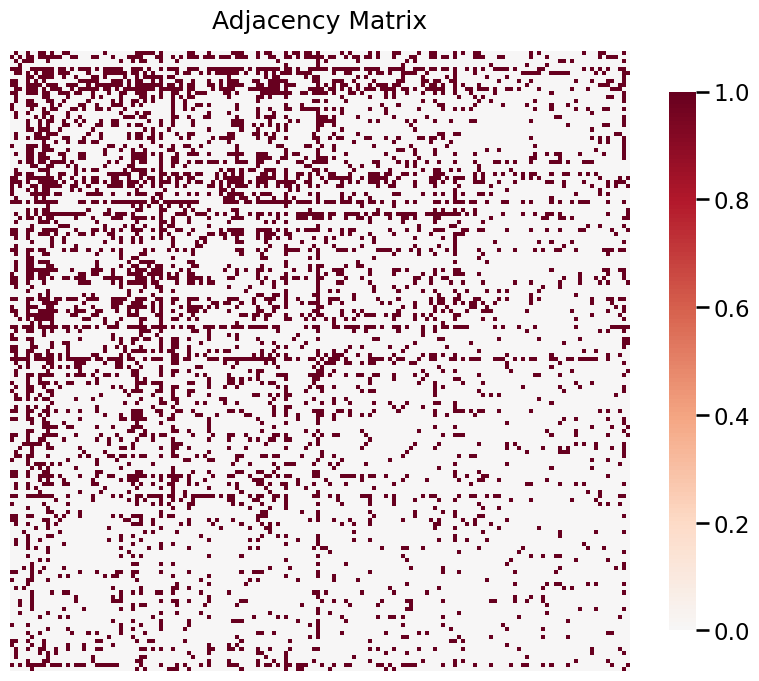

In [205]:
# heatmap
heatmap(adj, title="Adjacency Matrix")

In [206]:
from bokeh.plotting import output_notebook, show, figure, ColumnDataSource
from bokeh.models import HoverTool, LabelSet

def plot_graph_embedding_bokeh(G, X, title="Interactive ASE Embedding (raw) - Hover to see node names"):
    """
    G: networkx.Graph
    X: np.ndarray, shape (n_nodes, 2)
    """
    output_notebook()
    node_names = list(G.nodes())
    node_degrees = [G.degree(node) for node in node_names]
    node_sizes = [max(5, min(d * 2, 30)) for d in node_degrees]
    source = ColumnDataSource(
        data=dict(
            x=X[:, 0],
            y=X[:, 1],
            names=node_names,
            degrees=node_degrees,
            sizes=node_sizes,
        )
    )
    p = figure(
        width=800,
        height=600,
        title=title,
        tools="pan,wheel_zoom,box_zoom,reset,hover,save",
    )
    hover = p.select_one(HoverTool)
    hover.tooltips = [
        ("Node", "@names"),
        ("Degree", "@degrees"),
        ("X", "@x{0.000}"),
        ("Y", "@y{0.000}"),
    ]
    p.circle(
        "x",
        "y",
        source=source,
        size="sizes",
        color="darkblue",
        alpha=0.7,
        line_color="white",
        line_width=1,
    )
    labels = LabelSet(
        x="x",
        y="y",
        text="names",
        x_offset=8,
        y_offset=8,
        source=source,
        text_font_size="9pt",
        text_color="black",
        background_fill_color="white",
        background_fill_alpha=0.8,
    )
    p.add_layout(labels)
    show(p)

In [207]:
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import pearsonr, spearmanr

def graph_stats_df(G, X):
    # G: networkx.Graph, X: np.ndarray (n_nodes, 2)
    stats = {
        "degree": pd.Series(dict(G.degree())),
        "clustering": pd.Series(nx.clustering(G)),
        "closeness": pd.Series(nx.closeness_centrality(G)),
        "eigenvector": pd.Series(nx.eigenvector_centrality(G)),
        "pagerank": pd.Series(nx.pagerank(G)),
    }
    df = pd.DataFrame(stats)
    df["log_degree"] = np.log1p(df["degree"])
    df["x_coord"] = X[:, 0]
    df["y_coord"] = X[:, 1]
    return df

def print_embedding_corr_table(G, X):
    stats_to_plot = ["degree", "clustering", "closeness", "eigenvector", "pagerank"]
    df = graph_stats_df(G, X)
    corr_results = [
        {
            "statistic": stat,
            "x_pearson": pearsonr(df["x_coord"], df[stat])[0],
            "x_p_value": pearsonr(df["x_coord"], df[stat])[1],
            "y_pearson": pearsonr(df["y_coord"], df[stat])[0],
            "y_p_value": pearsonr(df["y_coord"], df[stat])[1],
            "x_spearman": spearmanr(df["x_coord"], df[stat])[0],
            "y_spearman": spearmanr(df["y_coord"], df[stat])[0],
        }
        for stat in stats_to_plot
    ]
    corr_df = pd.DataFrame(corr_results)
    print("Correlation Analysis: Embedding Dimensions vs Graph Statistics")
    print("=" * 70)
    print(corr_df.round(3))

def plot_embedding_corr_heatmap(G, X):
    stats_to_plot = ["degree", "clustering", "closeness", "eigenvector", "pagerank"]
    df = graph_stats_df(G, X)
    coord_cols = [f"x_coord_{i}" for i in range(X.shape[1])]
    for i in range(X.shape[1]):
        df[f"x_coord_{i}"] = X[:, i]
    cols = coord_cols + stats_to_plot
    corr_matrix = df[cols].corr()
    mask = np.triu(np.ones_like(corr_matrix, dtype=bool)) | np.eye(corr_matrix.shape[0], dtype=bool)
    plt.figure(figsize=(2 + len(cols), 2 + len(cols)))
    sns.heatmap(
        corr_matrix, mask=mask, annot=True, cmap="coolwarm", center=0, square=True, linewidths=0.5, cbar=True
    )
    plt.title("Correlation Matrix: Embedding Coordinates vs Graph Statistics (Lower Triangle, No Diagonal)")
    plt.tight_layout()
    plt.show()

stats_to_plot = ["degree", "clustering", "closeness", "eigenvector", "pagerank"]


/Users/frsc/miniconda3/envs/plot_social_fabric_env/lib/python3.11/site-packages/seaborn/axisgrid.py:1513: UserWarning: Ignoring `palette` because no `hue` variable has been assigned.
  func(x=vector, **plot_kwargs)
/Users/frsc/miniconda3/envs/plot_social_fabric_env/lib/python3.11/site-packages/seaborn/axisgrid.py:1513: UserWarning: Ignoring `palette` because no `hue` variable has been assigned.
  func(x=vector, **plot_kwargs)
/Users/frsc/miniconda3/envs/plot_social_fabric_env/lib/python3.11/site-packages/seaborn/axisgrid.py:1513: UserWarning: Ignoring `palette` because no `hue` variable has been assigned.
  func(x=vector, **plot_kwargs)
/Users/frsc/miniconda3/envs/plot_social_fabric_env/lib/python3.11/site-packages/seaborn/axisgrid.py:1615: UserWarning: Ignoring `palette` because no `hue` variable has been assigned.
  func(x=x, y=y, **kwargs)
/Users/frsc/miniconda3/envs/plot_social_fabric_env/lib/python3.11/site-packages/seaborn/axisgrid.py:1615: UserWarning: Ignoring `palette` because

Text(0.5, 0.98, 'Adjacency Spectral Embedding (raw)')

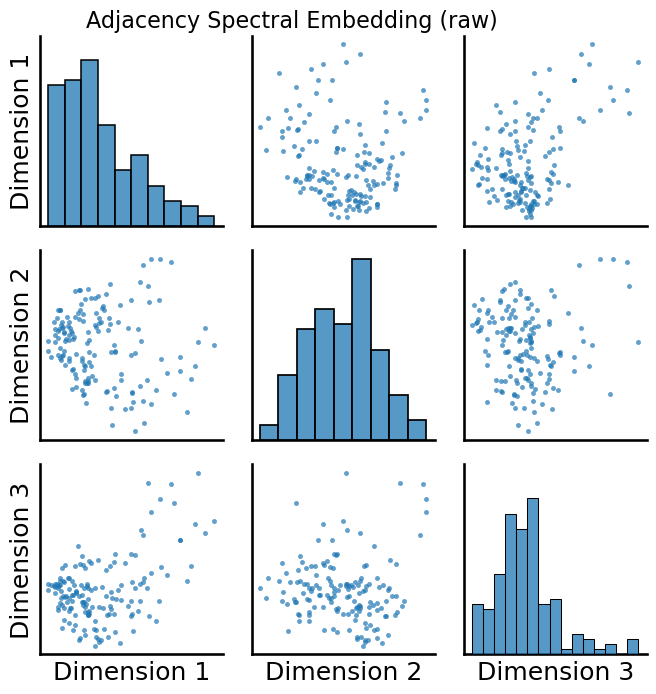

In [208]:
# Non-log transformed ASE
ase_raw = AdjacencySpectralEmbed(n_components=3)
X_raw = ase_raw.fit_transform(adj_sym)
plot_raw = pairplot(X_raw, title="Adjacency Spectral Embedding (raw)")
plot_raw.fig.suptitle("Adjacency Spectral Embedding (raw)", fontsize=16)


In [209]:
plot_graph_embedding_bokeh(G_undirected, X_raw)


Loading BokehJS ...

In [210]:
# the x-axis seems to be the degree of the node in the graph but holy shit it looks like the y-axis is something like how "meditation-y" an account is (up) vs how "techy" (down) - it's not perfect especially bc it's only 1 week of tweets but it's my best hypothesis so far

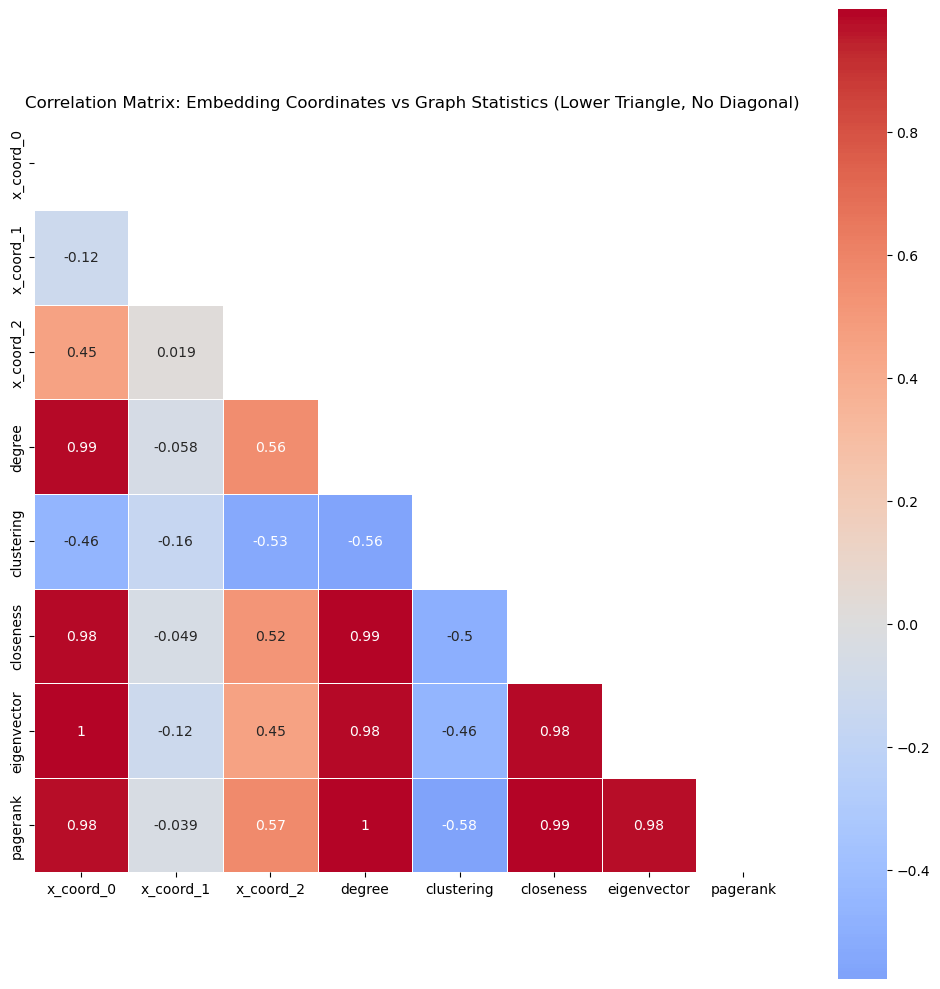

In [211]:
plot_embedding_corr_heatmap(G_undirected, X_raw)



In [212]:
X_raw[:,1:3].shape

(154, 2)

In [213]:
#  what about the 3rd principal component?
plot_graph_embedding_bokeh(G_undirected, X_raw[:,1:3])

Loading BokehJS ...

/Users/frsc/miniconda3/envs/plot_social_fabric_env/lib/python3.11/site-packages/seaborn/axisgrid.py:1513: UserWarning: Ignoring `palette` because no `hue` variable has been assigned.
  func(x=vector, **plot_kwargs)
/Users/frsc/miniconda3/envs/plot_social_fabric_env/lib/python3.11/site-packages/seaborn/axisgrid.py:1513: UserWarning: Ignoring `palette` because no `hue` variable has been assigned.
  func(x=vector, **plot_kwargs)
/Users/frsc/miniconda3/envs/plot_social_fabric_env/lib/python3.11/site-packages/seaborn/axisgrid.py:1615: UserWarning: Ignoring `palette` because no `hue` variable has been assigned.
  func(x=x, y=y, **kwargs)
/Users/frsc/miniconda3/envs/plot_social_fabric_env/lib/python3.11/site-packages/seaborn/axisgrid.py:1615: UserWarning: Ignoring `palette` because no `hue` variable has been assigned.
  func(x=x, y=y, **kwargs)


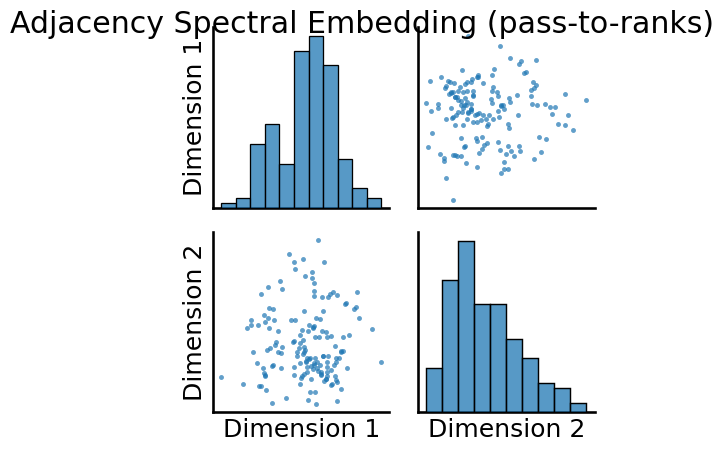

In [214]:
# # let's try the pass-to-rank trick
from scipy.stats import rankdata
from graspologic.embed import AdjacencySpectralEmbed

# 1. build & symmetrise adjacency
adj     = nx.to_numpy_array(G_undirected)
adj_sym = (adj + adj.T) / 2

# 2. pass-to-ranks (global ranks, then [0,1])
r = rankdata(adj_sym.ravel(), method="ordinal").astype(float)
ptr = r.reshape(adj_sym.shape)
ptr /= ptr.max()
ptr = (ptr + ptr.T) / 2        # enforce perfect symmetry

# 3. spectral embedding
ase = AdjacencySpectralEmbed(n_components=2)
X_ranked   = ase.fit_transform(ptr)

plot_raw = pairplot(X_ranked, title="Adjacency Spectral Embedding (pass-to-ranks)")



In [215]:
plot_graph_embedding_bokeh(G_undirected, X_ranked)

Loading BokehJS ...

In [216]:
# I can't tell if the X azxis axis has any meaning.... but the shape of the blob seems more reasonable...

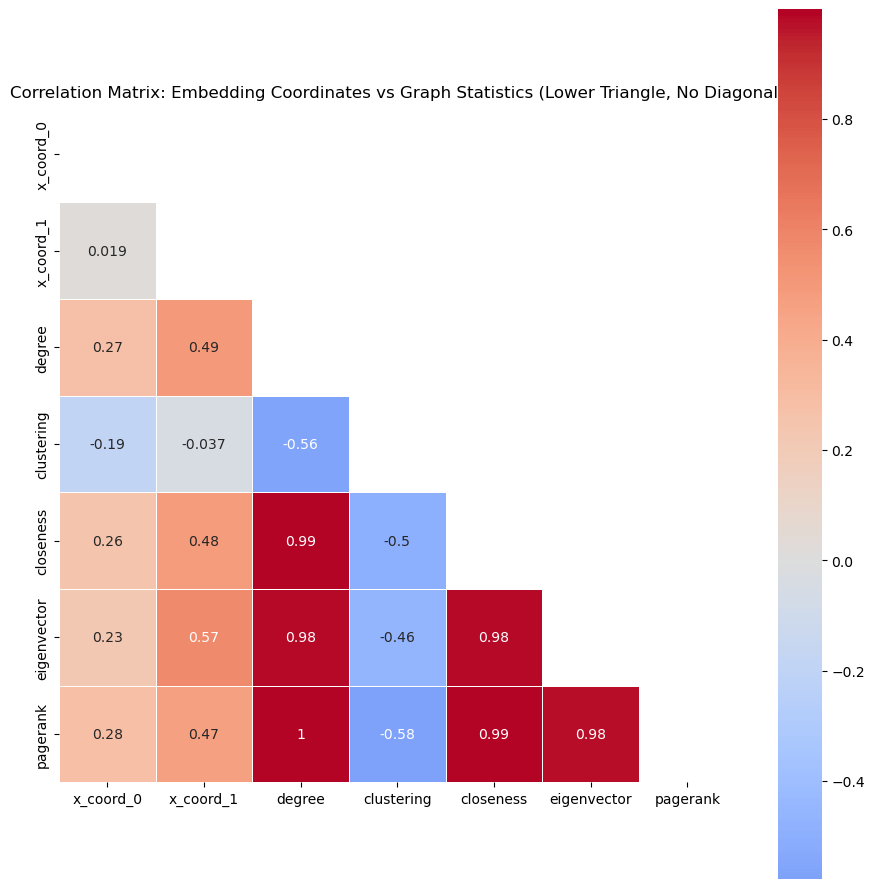

In [217]:
plot_embedding_corr_heatmap(G_undirected, X_ranked)


In [218]:
lsae = LaplacianSpectralEmbed(n_components=2)
X_lsae = lsae.fit_transform(adj_sym)


/Users/frsc/miniconda3/envs/plot_social_fabric_env/lib/python3.11/site-packages/seaborn/axisgrid.py:1513: UserWarning: Ignoring `palette` because no `hue` variable has been assigned.
  func(x=vector, **plot_kwargs)
/Users/frsc/miniconda3/envs/plot_social_fabric_env/lib/python3.11/site-packages/seaborn/axisgrid.py:1513: UserWarning: Ignoring `palette` because no `hue` variable has been assigned.
  func(x=vector, **plot_kwargs)
/Users/frsc/miniconda3/envs/plot_social_fabric_env/lib/python3.11/site-packages/seaborn/axisgrid.py:1615: UserWarning: Ignoring `palette` because no `hue` variable has been assigned.
  func(x=x, y=y, **kwargs)
/Users/frsc/miniconda3/envs/plot_social_fabric_env/lib/python3.11/site-packages/seaborn/axisgrid.py:1615: UserWarning: Ignoring `palette` because no `hue` variable has been assigned.
  func(x=x, y=y, **kwargs)


Text(0.5, 0.98, 'Laplacian Spectral Embedding (2 components)')

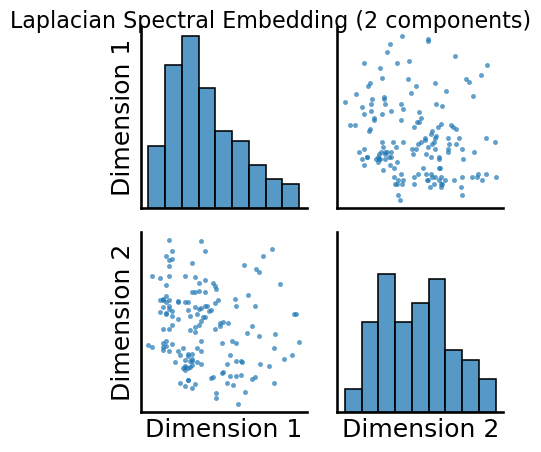

In [219]:
plot = pairplot(X_lsae, title="Laplacian Spectral Embedding (2 components)")
plot.fig.suptitle("Laplacian Spectral Embedding (2 components)", fontsize=16)

In [220]:
plot_graph_embedding_bokeh(G_undirected, X_lsae)


Loading BokehJS ...

In [221]:
# looks like non laplacian ASE but with 2 weird outliers

In [222]:
import matplotlib.pyplot as plt

# plot degree distribution
degrees = pd.Series(dict(G_undirected.degree())).sort_values(ascending=False)


In [223]:
lsa = LaplacianSpectralEmbed(form="R-DAD", n_components=2)
X_lsa_rdad = lsa.fit_transform(adj_sym)

/Users/frsc/miniconda3/envs/plot_social_fabric_env/lib/python3.11/site-packages/seaborn/axisgrid.py:1513: UserWarning: Ignoring `palette` because no `hue` variable has been assigned.
  func(x=vector, **plot_kwargs)
/Users/frsc/miniconda3/envs/plot_social_fabric_env/lib/python3.11/site-packages/seaborn/axisgrid.py:1513: UserWarning: Ignoring `palette` because no `hue` variable has been assigned.
  func(x=vector, **plot_kwargs)
/Users/frsc/miniconda3/envs/plot_social_fabric_env/lib/python3.11/site-packages/seaborn/axisgrid.py:1615: UserWarning: Ignoring `palette` because no `hue` variable has been assigned.
  func(x=x, y=y, **kwargs)
/Users/frsc/miniconda3/envs/plot_social_fabric_env/lib/python3.11/site-packages/seaborn/axisgrid.py:1615: UserWarning: Ignoring `palette` because no `hue` variable has been assigned.
  func(x=x, y=y, **kwargs)


Text(0.5, 0.98, 'Laplacian Spectral Embedding (R-DAD form)')

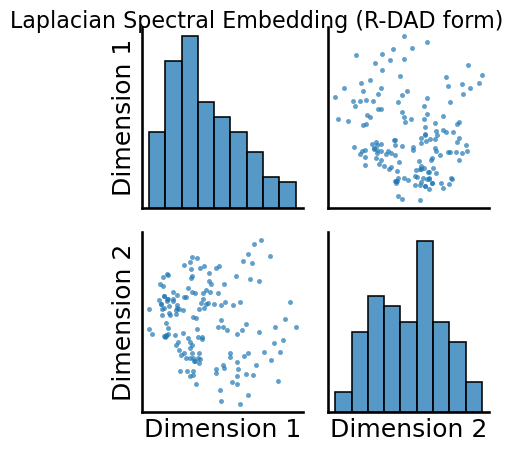

In [224]:
plot = pairplot(X_lsa_rdad, title="Laplacian Spectral Embedding (R-DAD form)")
plot.fig.suptitle("Laplacian Spectral Embedding (R-DAD form)", fontsize=16)

In [225]:
#  can't tell much of a difference

/Users/frsc/miniconda3/envs/plot_social_fabric_env/lib/python3.11/site-packages/sklearn/metrics/pairwise.py:2463: DataConversionWarning: Data was converted to boolean for metric jaccard
  warnings.warn(msg, DataConversionWarning)
/Users/frsc/miniconda3/envs/plot_social_fabric_env/lib/python3.11/site-packages/seaborn/axisgrid.py:1513: UserWarning: Ignoring `palette` because no `hue` variable has been assigned.
  func(x=vector, **plot_kwargs)
/Users/frsc/miniconda3/envs/plot_social_fabric_env/lib/python3.11/site-packages/seaborn/axisgrid.py:1513: UserWarning: Ignoring `palette` because no `hue` variable has been assigned.
  func(x=vector, **plot_kwargs)
/Users/frsc/miniconda3/envs/plot_social_fabric_env/lib/python3.11/site-packages/seaborn/axisgrid.py:1615: UserWarning: Ignoring `palette` because no `hue` variable has been assigned.
  func(x=x, y=y, **kwargs)
/Users/frsc/miniconda3/envs/plot_social_fabric_env/lib/python3.11/site-packages/seaborn/axisgrid.py:1615: UserWarning: Ignoring `p

Text(0.5, 0.98, 'Adjacency Spectral Embedding (Jaccard similarity)')

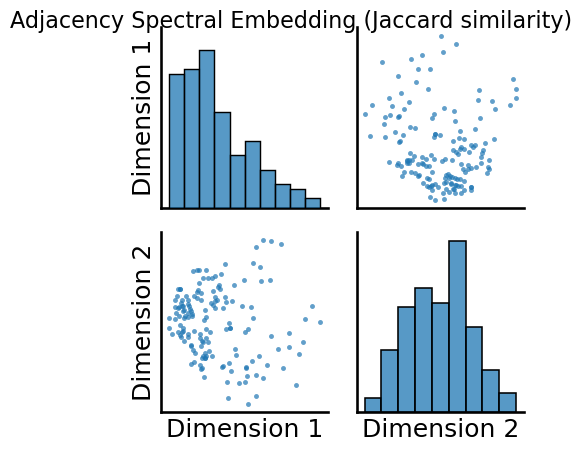

In [226]:
from sklearn.metrics import pairwise_distances

A = nx.to_numpy_array(G_undirected)
sim = 1 - pairwise_distances(A, metric="jaccard")
X_jaccard_sim = AdjacencySpectralEmbed(n_components=2).fit_transform(sim)
plot = pairplot(X, title="Adjacency Spectral Embedding (Jaccard similarity)")
plot.fig.suptitle("Adjacency Spectral Embedding (Jaccard similarity)", fontsize=16)

In [227]:
plot_graph_embedding_bokeh(G_undirected, X_jaccard_sim)


Loading BokehJS ...

In [228]:
# the others look the same but this one kinda looks more like a 3 pointed simplex, are there 3 distinguishable coordinates?

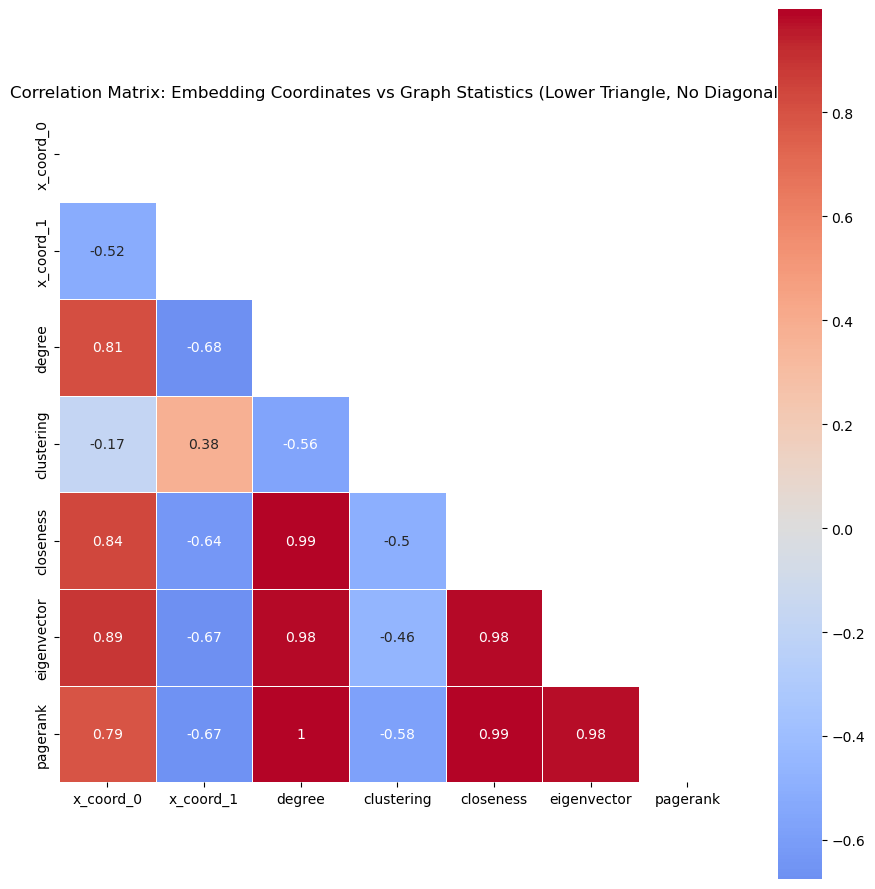

In [229]:
plot_embedding_corr_heatmap(G_undirected, X_jaccard_sim)

In [230]:
# fascinating! so jaccard similarity actually gives us closeness centrality and clustering coefficient / degree, AND a third thing? I can't tell what tho

# okay so the diagonal y=-x diagonal is the degree - and then a component of X that correlates with closeness centrality, or how ~ close a user is to everyone else; and a component of y that correlates w clustering coefficient or how cliquey a node's neighborhood is. I don't know the small accounts at the extremes to judge well enough

In [231]:
# I wonder if the pass-to-rank trick helps us here

In [232]:
# --- Node2Vec embedding with UMAP 2D projection ---------------------------
import umap

node2vec = Node2Vec(
    G_undirected,
    dimensions=64,
    walk_length=20,
    num_walks=200,
    workers=4,
    p=1,
    q=1,
    seed=42,
)
n2v_model = node2vec.fit(window=10, min_count=1, epochs=1)
nodes = list(G_undirected.nodes())
X_n2v = np.array([n2v_model.wv[str(node)] for node in nodes])

Computing transition probabilities:   0%|          | 0/154 [00:00<?, ?it/s]

Generating walks (CPU: 4): 100%|██████████| 50/50 [00:01<00:00, 26.85it/s]


/Users/frsc/miniconda3/envs/plot_social_fabric_env/lib/python3.11/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(
/Users/frsc/miniconda3/envs/plot_social_fabric_env/lib/python3.11/site-packages/seaborn/axisgrid.py:1513: UserWarning: Ignoring `palette` because no `hue` variable has been assigned.
  func(x=vector, **plot_kwargs)
/Users/frsc/miniconda3/envs/plot_social_fabric_env/lib/python3.11/site-packages/seaborn/axisgrid.py:1513: UserWarning: Ignoring `palette` because no `hue` variable has been assigned.
  func(x=vector, **plot_kwargs)
/Users/frsc/miniconda3/envs/plot_social_fabric_env/lib/python3.11/site-packages/seaborn/axisgrid.py:1615: UserWarning: Ignoring `palette` because no `hue` variable has been assigned.
  func(x=x, y=y, **kwargs)
/Users/frsc/miniconda3/envs/plot_social_fabric_env/lib/python3.11/site-packages/seaborn/axisgrid.py:1615: UserWarning: Ignoring `palette` because no `hue`

Text(0.5, 0.98, 'Node2Vec Embedding (UMAP to 2D)')

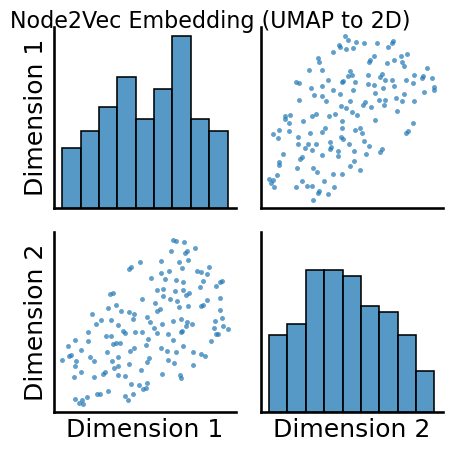

In [233]:
# refresh umap import in jupyter cell

X_n2v_2d = umap.UMAP(n_components=2, random_state=42).fit_transform(X_n2v)
plot = pairplot(X_n2v_2d, title="Node2Vec Embedding (UMAP to 2D)")
plot.fig.suptitle("Node2Vec Embedding (UMAP to 2D)", fontsize=16)



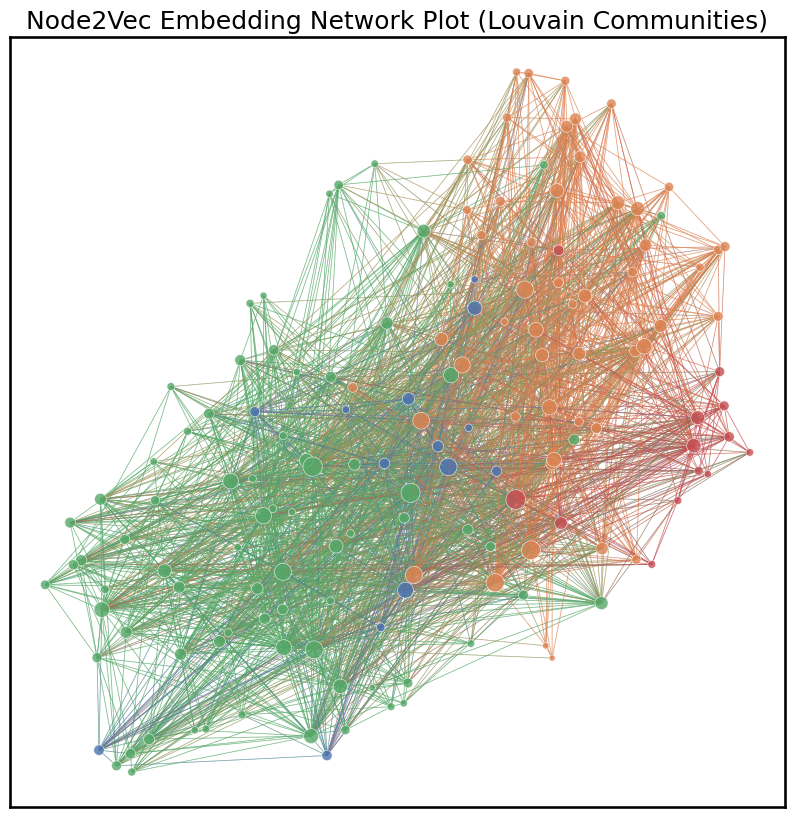

In [234]:
from graspologic.plot.plot import networkplot
import networkx.algorithms.community as nx_comm

# Use Louvain community detection on the graph structure
communities = nx_comm.louvain_communities(G_undirected)
n_clusters = len(communities)

# Create cluster labels mapping
cluster_labels = np.zeros(G_undirected.number_of_nodes(), dtype=int)
node_list = list(G_undirected.nodes())
for cluster_id, community in enumerate(communities):
    for node in community:
        node_idx = node_list.index(node)
        cluster_labels[node_idx] = cluster_id

x_pos = X_n2v_2d[:, 0]
y_pos = X_n2v_2d[:, 1]
degrees = np.sum(adj_sym, axis=0)
node_ids = list(G_undirected.nodes())

plot = networkplot(
    adjacency=adj_sym,
    x=x_pos,
    y=y_pos,
    node_hue=cluster_labels,
    palette="deep",
    node_size=degrees,
    node_sizes=(20, 200),
    edge_hue="source",
    edge_alpha=0.5,
    edge_linewidth=0.5,
    title="Node2Vec Embedding Network Plot (Louvain Communities)",
)


<img src='data:image/png;base64,iVBORw0KGgoAAAANSUhEUgAAAEAAAABACAYAAACqaXHeAAAABHNCSVQICAgIfAhkiAAAAAlwSFlz
AAAB+wAAAfsBxc2miwAAABl0RVh0U29mdHdhcmUAd3d3Lmlua3NjYXBlLm9yZ5vuPBoAAA6zSURB
VHic7ZtpeFRVmsf/5966taWqUlUJ2UioBBJiIBAwCZtog9IOgjqACsogKtqirT2ttt069nQ/zDzt
tI4+CrJIREFaFgWhBXpUNhHZQoKBkIUASchWla1S+3ar7r1nPkDaCAnZKoQP/D7mnPOe9/xy76n3
nFSAW9ziFoPFNED2LLK5wcyBDObkb8ZkxuaoSYlI6ZcOKq1eWFdedqNzGHQBk9RMEwFAASkk0Xw3
ETacDNi2vtvc7L0ROdw0AjoSotQVkKSvHQz/wRO1lScGModBFbDMaNRN1A4tUBCS3lk7BWhQkgpD
lG4852/+7DWr1R3uHAZVQDsbh6ZPN7CyxUrCzJMRouusj0ipRwD2uKm0Zn5d2dFwzX1TCGhnmdGo
G62Nna+isiUqhkzuKrkQaJlPEv5mFl2fvGg2t/VnzkEV8F5ioioOEWkLG86fvbpthynjdhXYZziQ
x1hC9J2NFyi8vCTt91Fh04KGip0AaG9zuCk2wQCVyoNU3Hjezee9bq92duzzTmxsRJoy+jEZZZYo
GTKJ6SJngdJqAfRzpze0+jHreUtPc7gpBLQnIYK6BYp/uGhw9YK688eu7v95ysgshcg9qSLMo3JC
4jqLKQFBgdKDPoQ+Pltb8dUyQLpeDjeVgI6EgLIQFT5tEl3rn2losHVsexbZ3EyT9wE1uGdkIPcy
BGxn8QUq1QrA5nqW5i2tLqvrrM9NK6AdkVIvL9E9bZL/oyfMVd/jqvc8LylzRBKDJSzIExwhQzuL
QYGQj4rHfFTc8mUdu3E7yoLtbTe9gI4EqVgVkug2i5+uXGo919ixbRog+3fTbQ8qJe4ZOYNfMoTI
OoshUNosgO60AisX15aeI2PSIp5KiFLI9ubb1vV3Qb2ltwLakUCDAkWX7/nHKRmmGIl9VgYsUhJm
2NXjKYADtM1ygne9QQDIXlk49FBstMKx66D1v4+XuQr7vqTe0VcBHQlRWiOCbmmSYe2SqtL6q5rJ
zsTb7lKx3FKOYC4DoqyS/B5bvLPxvD9Qtf6saxYLQGJErmDOdOMr/zo96km1nElr8bmPOBwI9COv
HnFPRIwmkSOv9kcAS4heRsidOkpeWBgZM+UBrTFAXNYL5Vf2ii9c1trNzpYdaoVil3WIc+wdk+gQ
noie3ecCcxt9ITcLAPWt/laGEO/9U6PmzZkenTtsSMQ8uYywJVW+grCstAvCIaAdArAsIWkRDDs/
KzLm2YcjY1Lv0UdW73HabE9n6V66cxSzfEmuJssTpKGVp+0vHq73FwL46eOjpMpbRAnNmJFrGJNu
Ukf9Yrz+3rghiumCKNXXWPhLYcjxGsIpoCMsIRoFITkW8AuyM8jC1+/QLx4bozCEJIq38+1rtpR6
V/yzb8eBlRb3fo5l783N0CWolAzJHaVNzkrTzlEp2bQ2q3TC5gn6wpnoQAmwSiGh2GitnTmVMc5O
UyfKWUKCIsU7+fZDKwqdT6DDpvkzAX4/+AMFjk0tDp5GRXLpQ2MUmhgDp5gxQT8+Y7hyPsMi8uxF
71H0oebujHALECjFKaW9Lm68n18wXp2kVzIcABytD5iXFzg+WVXkegpAsOOYziqo0OkK76GyquC3
ltZAzMhhqlSNmmWTE5T6e3IN05ITFLM4GdN0vtZ3ob8Jh1NAKXFbm5PtLU/eqTSlGjkNAJjdgn/N
aedXa0tdi7+t9G0FIF49rtMSEgAs1kDLkTPO7ebm4IUWeyh1bKomXqlgMG6kJmHcSM0clYLJ8XtR
1GTnbV3F6I5wCGikAb402npp1h1s7LQUZZSMIfALFOuL3UUrfnS8+rez7v9qcold5tilgHbO1fjK
9ubb17u9oshxzMiUBKXWqJNxd+fqb0tLVs4lILFnK71H0Ind7uiPgACVcFJlrb0tV6DzxqqTIhUM
CwDf1/rrVhTa33/3pGPxJYdQ2l2cbgVcQSosdx8uqnDtbGjh9SlDVSMNWhlnilfqZk42Th2ZpLpf
xrHec5e815zrr0dfBZSwzkZfqsv+1FS1KUknUwPARVvItfKUY+cn57yP7qv07UE3p8B2uhUwLk09
e0SCOrK+hbdYHYLjRIl71wWzv9jpEoeOHhGRrJAzyEyNiJuUqX0g2sBN5kGK6y2Blp5M3lsB9Qh4
y2Ja6x6+i0ucmKgwMATwhSjdUu49tKrQ/pvN5d53ml2CGwCmJipmKjgmyuaXzNeL2a0AkQ01Th5j
2DktO3Jyk8f9vcOBQHV94OK+fPumJmvQHxJoWkaKWq9Vs+yUsbq0zGT1I4RgeH2b5wef7+c7bl8F
eKgoHVVZa8ZPEORzR6sT1BzDUAD/d9F78e2Tzv99v8D+fLVTqAKAsbGamKey1Mt9Ann4eH3gTXTz
idWtAJ8PQWOk7NzSeQn/OTHDuEikVF1R4z8BQCy+6D1aWRfY0tTGG2OM8rRoPaeIj5ZHzJxszElN
VM8K8JS5WOfv8mzRnQAKoEhmt8gyPM4lU9SmBK1MCQBnW4KONT86v1hZ1PbwSXPw4JWussVjtH9Y
NCoiL9UoH/6PSu8jFrfY2t36erQHXLIEakMi1SydmzB31h3GGXFDFNPaK8Rme9B79Ixrd0WN+1ij
NRQ/doRmuFLBkHSTOm5GruG+pFjFdAmorG4IXH1Qua6ASniclfFtDYt+oUjKipPrCQB7QBQ2lrgP
fFzm+9XWUtcqJ3/5vDLDpJ79XHZk3u8nGZ42qlj1+ydtbxysCezrydp6ugmipNJ7WBPB5tydY0jP
HaVNzs3QzeE4ZpTbI+ZbnSFPbVOw9vsfnVvqWnirPyCNGD08IlqtYkh2hjZ5dErEQzoNm+6ykyOt
Lt5/PQEuSRRKo22VkydK+vvS1XEKlhCJAnsqvcVvH7f/ZU2R67eXbMEGAMiIV5oWZWiWvz5Fv2xG
sjqNJQRvn3Rs2lji/lNP19VjAQDgD7FHhujZB9OGqYxRkZxixgRDVlqS6uEOFaJUVu0rPFzctrnF
JqijImVp8dEKVWyUXDk92zAuMZ6bFwpBU1HrOw6AdhQgUooChb0+ItMbWJitSo5Ws3IAOGEOtL53
0vHZih9sC4vtofZ7Qu6523V/fmGcds1TY3V36pUsBwAbSlxnVh2xLfAD/IAIMDf7XYIkNmXfpp2l
18rkAJAy9HKFaIr/qULkeQQKy9zf1JgDB2uaeFNGijo5QsUyacNUUTOnGO42xSnv4oOwpDi1zYkc
efUc3I5Gk6PhyTuVKaOGyLUAYPGIoY9Pu/atL/L92+4q9wbflRJ2Trpm/jPjdBtfnqB/dIThcl8A
KG7hbRuKnb8qsQsVvVlTrwQAQMUlf3kwJI24Z4JhPMtcfng5GcH49GsrxJpGvvHIaeem2ma+KSjQ
lIwUdYyCY8j4dE1KzijNnIP2llF2wcXNnsoapw9XxsgYAl6k+KzUXbi2yP3KR2ecf6z3BFsBICdW
nvnIaG3eHybqX7vbpEqUMT+9OL4Qpe8VON7dXuFd39v19FoAABRVePbGGuXTszO0P7tu6lghUonE
llRdrhArLvmKdh9u29jcFiRRkfLUxBiFNiqSU9icoZQHo5mYBI1MBgBH6wMNb+U7Pnw337H4gi1Y
ciWs+uks3Z9fztUvfzxTm9Ne8XXkvQLHNytOOZeiD4e0PgkAIAYCYknKUNUDSXEKzdWNpnil7r4p
xqkjTarZMtk/K8TQ6Qve78qqvXurGwIJqcOUKfUWHsm8KGvxSP68YudXq4pcj39X49uOK2X142O0
Tz5/u/7TVybqH0rSya6ZBwD21/gubbrgWdDgEOx9W
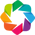

In [235]:
import networkx as nx
import holoviews as hv
from holoviews import opts
import holoviews.operation.datashader as hd

hv.extension("bokeh")



In [236]:
def get_layout(graph, layout_type, X=None):
    if layout_type == "node2vec" and X is not None:
        node_list = list(graph.nodes())
        return {node: (X[i, 0], X[i, 1]) for i, node in enumerate(node_list)}
    elif layout_type == "force_directed":
        return nx.layout.fruchterman_reingold_layout(graph, seed=42)
    else:
        raise ValueError(f"Unknown layout_type: {layout_type}")

from bokeh.plotting import figure, from_networkx
from bokeh.models import MultiLine, HoverTool, Scatter
from bokeh.palettes import viridis

def plot_layout(graph, layout_type, X=None, cluster_labels=None, title=""):
    layout = get_layout(graph, layout_type, X)
    node_list = list(graph.nodes())
    cluster_labels = cluster_labels if cluster_labels is not None else np.zeros(len(node_list), dtype=int)
    color_map = viridis(len(set(cluster_labels)))
    node_color = [color_map[cl] for cl in cluster_labels]

    G = graph.copy()
    nx.set_node_attributes(G, {n: layout[n] for n in node_list}, "pos")
    nx.set_node_attributes(G, {n: node_color[i] for i, n in enumerate(node_list)}, "color")
    nx.set_node_attributes(G, {n: cluster_labels[i] for i, n in enumerate(node_list)}, "cluster")
    nx.set_node_attributes(G, {n: str(n) for n in node_list}, "label")

    plot = figure(title=title, width=800, height=800, x_axis_type=None, y_axis_type=None, tools="pan,wheel_zoom,reset,save")
    plot.grid.grid_line_color = None

    graph_renderer = from_networkx(G, layout, scale=1, center=(0, 0))
    graph_renderer.node_renderer.glyph = Scatter(size=12, fill_color="color")
    graph_renderer.edge_renderer.glyph = MultiLine(line_alpha=0.3, line_width=0.5)

    node_degrees = dict(graph.degree())
    top_percentile = np.percentile(list(node_degrees.values()), 80)
    label_nodes = [n for n in node_list if node_degrees[n] >= top_percentile]
    label_x = [layout[n][0] for n in label_nodes]
    label_y = [layout[n][1] for n in label_nodes]
    label_names = [str(n) for n in label_nodes]
    if label_nodes:
        source = ColumnDataSource(dict(x=label_x, y=label_y, name=label_names))
        labels = LabelSet(x="x", y="y", text="name", source=source, text_font_size="10pt", text_color="black")
        plot.add_layout(labels)
        
        # Add hover tool for node labels
    hover = HoverTool(tooltips=[("Node", "@label"), ("Cluster", "@cluster")], renderers=[graph_renderer.node_renderer])
    plot.add_tools(hover)


    plot.renderers.append(graph_renderer)
    return plot

node2vec_plot = plot_layout(
    G_undirected,
    "node2vec",
    X=X_n2v_2d,
    cluster_labels=cluster_labels,
    title=f"Node2Vec Layout: @{ego_node} - Louvain Communities",
)

from bokeh.io import output_notebook, show
output_notebook()
show(node2vec_plot)

Loading BokehJS ...

In [239]:
# Show cluster info and top 5 nodes by total_replies_received for each cluster
cluster_info = pd.DataFrame(
    {"node": list(G_undirected.nodes()), "cluster": cluster_labels}
)
cluster_info = cluster_info.merge(
    user_df[["username", "total_replies_received"]],
    left_on="node",
    right_on="username",
    how="left"
)
cluster_counts = cluster_info.groupby("cluster").size().sort_values(ascending=False)
summary = [f"Louvain found {len(set(cluster_labels))} communities:",
           str(cluster_counts.head(10))]
for cl in cluster_counts.index:
    nodes = (
        cluster_info[cluster_info["cluster"] == cl]
        .sort_values("total_replies_received", ascending=False)
        .head(100)["node"]
        .tolist()
    )
    summary.append(f"Cluster {cl} top 5 nodes by replies received: {nodes}")
print('\n'.join(summary))


Louvain found 4 communities:
cluster
3    76
0    51
2    14
1    13
dtype: int64
Cluster 3 top 5 nodes by replies received: ['nosilverv', 'mimi10v3', 'eigenrobot', 'goblinodds', 'deepfates', 'strangestloop', 'pachabelcanon', 'PrinceVogel', 'eshear', 'selentelechia', 'algekalipso', 'bashu_thanks', 'slimepriestess', 'br___ian', 'aleksil79', 'sanjehorah', 'BLUNDERBUSSTED', 'daniellellecco', 'yashkaf', 'losingcontrol23', 'natural_hazard', 'loopholekid', 'forthrighter', 'panchromaticity', 'realtimeai', 'DanielleFong', 'SurrealistShip', 'xsphi', 'IaimforGOAT', 'nobu_hibiki', 'Lithros', 'mbateman', 'blisstweeting', 'AaronBergman18', 'DefenderOfBasic', 'levelsio', 'shakoistsLog', 'jd_pressman', 'voooooogel', 'LericDax', 'FriedKielbasa', 'moissanist', 'dpinkshadow', 'forshaper', 'demiurgently', 'AngularOcean', 'adic_9', 'imhinesmi', 'AbstractRevery', 'imperialauditor', 'kumbuchaqueen', 'tr_babb', 'TheZvi', 'peakexperiments', 'JustAnkurBagchi', 'IgorBrigadir', 'patio11', '_ceee_', 'poptimistici

In [238]:
from holoviews.operation.datashader import bundle_graph, datashade

# let's bundle and plot the network with holoviews
color_map = viridis(len(set(cluster_labels)))
node_color = [color_map[cl] for cl in cluster_labels]
# let's add cluster labels as metadata to G_undirected
nx.set_node_attributes(G_undirected, {n: cluster_labels[i] for i, n in enumerate(node_list)}, "cluster")

deg = dict(G_undirected.degree())
deg_thresh = np.percentile(list(deg.values()), 80)
nx.set_node_attributes(
    G_undirected,
    {n: str(n) if deg[n] >= deg_thresh else "" for n in node_list},
    "label"
)

graph = hv.Graph.from_networkx(G_undirected, get_layout(G_undirected, 'node2vec', X_n2v_2d))

labels = hv.Labels(graph.nodes, kdims=['x', 'y'], vdims=['label'])
# (graph * labels.opts(text_font_size='8pt', text_color='white', bgcolor='gray'))
kwargs = dict(width=200, height=200, xaxis=None, yaxis=None)
opts.defaults(opts.Nodes(**kwargs), opts.Graph(**kwargs))

graph.opts(cmap=color_map, node_color='cluster')
bundled = bundle_graph(graph)

(datashade(bundled, normalization='linear') * bundled.nodes  * labels.opts(text_font_size='8pt', text_color='white', bgcolor='gray')).opts(
    opts.Nodes(color='cluster', size=10, cmap=color_map, legend_position='right', width=800, height=800, bgcolor='lightblue')) 


BokehModel(combine_events=True, render_bundle={'docs_json': {'9a064920-23ec-4a40-9911-680f9bd48254': {'version…